# WISE process evaluation

**Notebook author: Urszula Jessen**

This notebook reproduces the three applications in **WISE: Actionable Norm-Based Scoring for Process Mining** by Urszula Jessen, Dirk Fahland and Francesca Zerbato. It covers all 38 result items and Figures 4–6.

The calculations use `wise.evaluation.paper` and verified source logs. Comparison tables report agreement at the declared precision, numerical differences and results that could not be computed. Numerical agreement establishes consistency of the calculations; interpretation also depends on the assessment rules and source records.


## 1. Environment and data

From the `notebooks` directory, install the dedicated environment and launch JupyterLab:

```sh
bash setup_environment.sh
bash start_jupyter.sh /path/to/public/logs
```

Select the **WISE paper (frozen)** kernel and run all cells. The launch command sets `WISE_PAPER_DATA`; no code-cell edits are required. Installation and data-source details are in [README.md](README.md).

The data directory must contain these files, which may be in subdirectories:

- `BPI_Challenge_2019.csv`
- `BPI_Challenge_2013_incidents.xes.gz`
- `BPI Challenge 2017.xes.gz`

The library verifies input identities. BPIC’19 requires the documented CSV export. Missing inputs remain marked **not computed** and cause the final verification to fail. Figures are displayed and exported to `outputs/`.


In [1]:
import os
from io import BytesIO
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

try:
    import wise
    from wise.evaluation import DataNotAvailable, paper
except ImportError:
    raise RuntimeError(
        "Run setup_environment.sh and select the WISE paper (frozen) kernel."
    ) from None

if wise.__version__ != "1.0.1" or len(getattr(paper, "ITEMS", {})) != 38:
    raise RuntimeError(
        "This notebook requires the frozen WISE 1.0.1 evaluation package."
    )
if not os.environ.get("WISE_PAPER_DATA"):
    raise RuntimeError(
        "Launch with start_jupyter.sh DATA_FOLDER or set WISE_PAPER_DATA."
    )

NOTEBOOK_ROOT = Path.cwd().resolve()
if not (NOTEBOOK_ROOT / "WISE_Evaluation.ipynb").is_file():
    raise RuntimeError("Run the notebook from its notebooks directory.")
OUTPUT_DIR = NOTEBOOK_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

In [2]:
def show_result(function):
    """Display a result or identify an unavailable source."""
    try:
        display(function())
    except DataNotAvailable:
        display(
            Markdown("**Not computed:** a required verified source is unavailable.")
        )


def show_figure(function, stem):
    """Display and export a figure from the assessed data."""
    try:
        figure = function()
    except DataNotAvailable:
        display(
            Markdown("**Not computed:** a required verified source is unavailable.")
        )
        return
    try:
        figure.savefig(OUTPUT_DIR / f"{stem}.png", dpi=220, bbox_inches="tight")
        figure.savefig(OUTPUT_DIR / f"{stem}.svg", bbox_inches="tight")
        with BytesIO() as image:
            figure.savefig(image, format="png", dpi=140, bbox_inches="tight")
            display(Image(data=image.getvalue()))
    finally:
        plt.close(figure)

## 2. Running examples and worked arithmetic

Tables 3–4 define the running norm and its five illustrative cases. The additional balance constraint is outside scope for all five cases. Finance and Logistics weights are renormalised over evaluated constraints. Outside scope, unavailable evidence and evaluated zero remain distinct.

The Section 3 example shows how invoice cases, business views and group priorities fit together. These constructed examples explain the method; they are separate from the empirical BPIC’19 assessment.

In [3]:
display(paper.table_3())

,layer,type,description,params,applicability,Finance,Logistics
id,,,,,,,
c1,Core completeness,presence,Require an invoice receipt,"{'activity': ['Record Invoice Receipt'], 'm': 1}",always,0.20,0.25
c2,Receipt-to-invoice timing,lag,Invoice timeliness: GR → INV within 10 days,"{'a': ['Record Goods Receipt'], 'b': ['Record ...",always,0.45,0.15
c3,Match consistency,balance,Amount consistency: invoiced amount matches re...,"{'attr_x': 'amount', 'activities_x': ['Record ...",always,0.20,0.05
c4,Match consistency,balance,GR amount consistency: ordered amount matches ...,"{'attr_x': 'amount', 'activities_x': ['Create ...",{'flow_type': ['DF1']},0.05,0.25
c5,Handling discipline,singularity,Limit delivery fragmentation,"{'activity': ['Record Goods Receipt'], 'k': 2,...",always,0.05,0.45
c6,Exception discipline,exclusion,Avoid invoice cancellations,{'activity': ['Cancel Invoice Receipt']},always,0.10,0.10


In [4]:
show_result(paper.item_01_table_4)

,non-zero violations,S(Finance),S(Logistics)
case,,,
σA,ν_c2 = 0.75,0.6625,0.8875
σB,ν_c5 = 0.6667,0.9667,0.7000
σC,ν_c3 = 0.65,0.8700,0.9675
σD,ν_c6 = 1,0.9000,0.9000
σE,"ν_c1 = 1, ν_c2 = 1, ν_c3 = 1",0.1500,0.5500


In [5]:
show_result(paper.item_02_worked_arithmetic)

,computed
quantity,
"sat(z; 10, 20) at z = 8",0.000000
"sat(z; 10, 20) at z = 15",0.250000
"sat(z; 10, 20) at z = 20",0.500000
"sat(z; 10, 20) at z = 30",1.000000
"lag constraint c2 (δ = 10 d, Δ = 20 d) at a lag in days of 10",0.000000
"lag constraint c2 (δ = 10 d, Δ = 20 d) at a lag in days of 20",0.500000
"lag constraint c2 (δ = 10 d, Δ = 20 d) at a lag in days of 30",1.000000
"occurrence limit c5 (k = 2, K = 3) at a count of 3",0.333333
"occurrence limit c5 (k = 2, K = 3) at a count of 4",0.666667


### Section 3 — invoice cases, views and priorities (item 41)

In [6]:
show_result(paper.item_41_illustration)

plant  release_limit  \
kind         row                                                           
case         A1                                   Plant A            1.0   
             A2                                   Plant A            1.0   
             B1                                   Plant B            0.0   
             B2                                   Plant B            0.0   
view weights Processing effort                        NaN            0.4   
             Financial control                        NaN            0.1   
slice        Plant A · Type X, Processing effort  Plant A            NaN   
             Plant B · Type X, Processing effort  Plant B            NaN   
             Plant B · Type X, Financial control  Plant B            NaN   
             Plant A · Type X, Financial control  Plant A            NaN   

                                                  no_forwarding  \
kind         row                                                  
case         A1                                             1.0   
             A2                                             0.0   
             B1                                             0.0   
             B2                                             0.0   
view weights Processing effort                              0.4   
             Financial control                              0.1   
slice        Plant A · Type X, Processing effort            NaN   
             Plant B · Type X, Processing effort            NaN   
             Plant B · Type X, Financial control            NaN   
             Plant A · Type X, Financial control            NaN   

                                                  release_record  \
kind         row                                                   
case         A1                                              0.0   
             A2                                              0.0   
             B1                                              1.0   
             B2                                              1.0   
view weights Processing effort                               0.2   
             Financial control                               0.8   
slice        Plant A · Type X, Processing effort             NaN   
             Plant B · Type X, Processing effort             NaN   
             Plant B · Type X, Financial control             NaN   
             Plant A · Type X, Financial control             NaN   

                                                  score, Processing effort  \
kind         row                                                             
case         A1                                                        0.2   
             A2                                                        0.6   
             B1                                                        0.8   
             B2                                                        0.8   
view weights Processing effort                                         NaN   
             Financial control                                         NaN   
slice        Plant A · Type X, Processing effort                       NaN   
             Plant B · Type X, Processing effort                       NaN   
             Plant B · Type X, Financial control                       NaN   
             Plant A · Type X, Financial control                       NaN   

                                                  score, Financial control  \
kind         row                                                             
case         A1                                                        0.8   
             A2                                                        0.9   
             B1                                                        0.2   
             B2                                                        0.2   
view weights Processing effort                                         NaN   
             Financial control    

## 3. Specifying the P2P assessment — Section 5.1

The scored case is a purchase-order item. Purchasing document, company, spend area and vendor describe whole-case context. The library preserves four flow categories and explicit missing group labels.

Table B1 declares the ten criteria, their evidence rules and view weights. Changing the view changes importance weights, not criterion assessments. The primary comparison uses flat scoring, case-count scaling, the scored-population reference and no small-group adjustment. A layer’s raw multiplier applies to every criterion in that layer; it does not allocate an equal share to each layer.

In [7]:
display(paper.table_b1())

,recorded condition,deviation scale,layer,scope,evidence,w(Balanced),w(Completion),w(Operations)
criterion,,,,,,,,
C01,No recorded invoice receipt,binary,Completion,non-consignment,"absence within recorded history, not proof of ...",1,3,1
C02,No recorded clearing,binary,Completion,non-consignment,"absence within recorded history, not proof of ...",1,3,1
C03,No recorded goods or service receipt,binary,Completion,DF1 or DF2,,1,3,1
C04,Long observed invoice-to-clearing lag,0 at 30; 1 at 90,Timing,non-consignment,both first timestamps observed and plausible; ...,1,2,1
C05,Invoice precedes goods or service receipt,binary,Timing,DF1,both first timestamps observed and plausible; ...,1,2,1
C06,Invoice-receipt cancellation recorded,binary,Rework,all,,1,1,2
C07,Price or quantity edits recorded,0 at 0; 1 at 3,Rework,all,,1,1,2
C08,Repeated invoice receipt,0 at 1; 1 at 4,Rework,non-consignment,,1,1,2
C09,Recorded user-attributed events,0 at 5; 1 at 15,Effort proxy,all,every event resource usable; a missing or unus...,1,1,3


### Source events, PO items and purchasing documents

In [8]:
show_result(paper.item_03_log_size)

events       1595923
po_items      251734
documents      76349
Name: BPIC'19, dtype: int64

### Case population by flow category

In [9]:
show_result(paper.item_04_flow_categories)

DF2            221010
DF1             15182
Consignment     14498
two_way          1044
Name: PO items, dtype: int64

### Company-by-spend-area groups

In [10]:
show_result(paper.item_05_slices)

30

### Scored population under each view

In [11]:
show_result(paper.item_06_scored_cases)

Balanced      251734
Completion    251734
Operations    251734
Name: scored PO items, dtype: int64

### Mean weighted evidence coverage under each view

In [12]:
show_result(paper.item_07_mean_coverage)

Balanced      0.787570
Completion    0.866370
Operations    0.669052
Name: mean coverage, dtype: float64

### Criterion weights and layer shares (item 40)

In [13]:
show_result(paper.item_40_view_weights)

,"raw weight per criterion, Balanced","raw weight per criterion, Completion","raw weight per criterion, Operations",layer share under Balanced
Completion,1.0,3.0,1.0,0.3
Timing,1.0,2.0,1.0,0.2
Rework,1.0,1.0,2.0,0.3
Effort proxy,1.0,1.0,3.0,0.2


## 4. Comparing and explaining investigation priorities — Section 5.2

The library compares group mean penalties with the scored population and computes the Priority Index. Read each priority beside its evidence coverage and usable endpoints: a low observed timing contribution may reflect limited timing evidence.

Layer contributions are signed. Negative offsets are included before the total is clipped at zero. Rounded plotted components need not sum exactly to a separately rounded total. The comparison identifies cases to investigate; it does not establish causes, financial losses or measured staffing effort.

### Balanced population mean penalty

In [14]:
show_result(paper.item_13_population_mean_penalty)

0.1013579109646243

### Packaging group priority

In [15]:
show_result(paper.item_14_packaging)

mean_penalty         0.117624
scored          109199.000000
gap                  0.016266
pi                1776.191040
Name: companyID_0000 / Packaging, dtype: float64

### Logistics group priority

In [16]:
show_result(paper.item_15_logistics)

mean_penalty       0.228143
scored          5242.000000
gap                0.126785
pi               664.607179
Name: companyID_0000 / Logistics, dtype: float64

### Group coverage

In [17]:
show_result(paper.item_16_slice_coverage)

companyID_0000 / Packaging    0.788831
companyID_0000 / Logistics    0.706683
Name: mean coverage, dtype: float64

### Signed layer contributions

In [18]:
show_result(paper.item_17_layer_contributions)

,Completion,Timing,Rework,Effort proxy,sum,Priority Index
companyID_0000 / Packaging,-332.420985,2365.436368,-267.950108,11.125766,1776.191040,1776.191040
companyID_0000 / Logistics,811.132774,-154.248298,10.535362,-2.812658,664.607179,664.607179


### Figure 4 — signed explanations on a common scale (item 18)

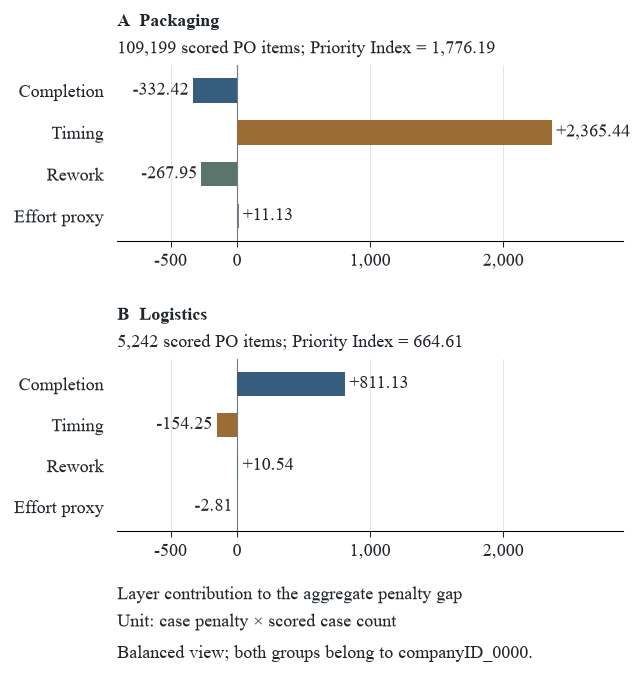

In [19]:
show_figure(paper.figure_4, "fig4_layers")

### Recorded Logistics absences (item 19)

In [20]:
show_result(paper.item_19_logistics_absences)

no_invoice_receipt    3260
no_clearing           3507
Name: companyID_0000 / Logistics, dtype: int64

### Packaging vendor concentration (item 20)

The concentration measure uses the sum of case penalties within vendor groups, not vendor Priority Indices.

In [21]:
show_result(paper.item_20_vendor_concentration)

vendors                   266
vendors_for_80_percent     16
Name: companyID_0000 / Packaging, dtype: int64

### C04 applicability and usable endpoints (item 35)

In [22]:
show_result(paper.item_35_c04_endpoints)

,applicable,usable endpoints
companyID_0000 / Logistics,5242,1734
companyID_0000 / Packaging,100635,76608


## 5. Tracing a priority to recorded evidence — Section 5.3

C04 uses the earliest successfully parsed invoice and clearing timestamps. The selected endpoints must pass the adapter’s plausibility checks and their interval must be non-negative. Coverage measures available in-scope weight; it does not certify that a log is complete.

Figure 5 compares the full library-produced interval distributions. The worked PO item then connects its timestamps, deviation, weighted contribution and score.

### C04-evaluable and positive Packaging items

In [23]:
show_result(paper.item_08_c04_evaluable)

evaluable    76608
positive     64068
Name: Packaging, C04, dtype: int64

### Evaluable populations and medians

In [24]:
show_result(paper.item_09_lag_medians)

,n,median_days
Packaging,76608,69.040972
Remaining groups,106661,28.929167


### The same comparison restricted to DF2

In [25]:
show_result(paper.item_10_lag_medians_df2)

,n,median_days
Packaging,73157,70.139583
Remaining groups,100142,29.101389


### Figure 5 — cumulative invoice-to-clearing interval distributions (item 11)

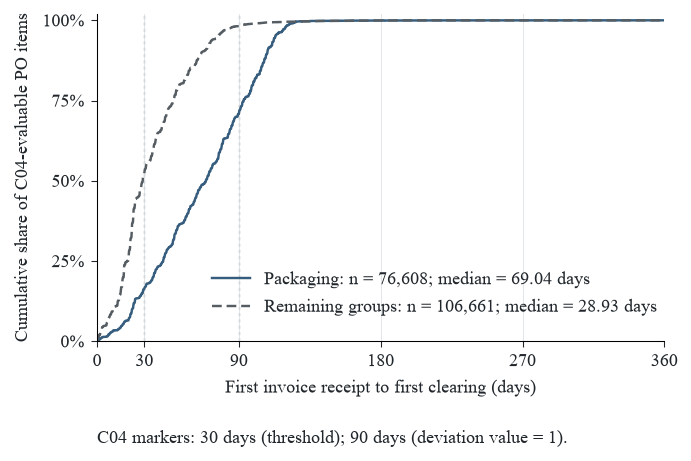

In [26]:
show_figure(paper.figure_5, "fig5_lag")

### Worked PO item and evidence states (item 12)

The library returns the selected item, endpoint timestamps, severity, weighted contribution, score and evidence coverage. Read them together to understand how this case was assessed.

In [27]:
show_result(paper.item_12_worked_po_item)

item                              4507005472_00040
first_invoice_receipt             2018-02-16 10:15
first_clearing                    2018-04-26 11:14
lag_days                                 69.040972
deviation                                 0.650683
evaluable_criteria                               7
contribution                              0.092955
other_nonzero                                    0
state.C05                             out_of_scope
state.C09                missing_resource_evidence
state.C10                missing_resource_evidence
score                                     0.907045
in_scope_criteria                                9
coverage                                  0.777778
group_median_days                        69.040972
Name: worked PO item, dtype: object

## 6. Comparing views and ranking choices — Section 5.4

The library returns purchasing-document shortlists, tie checks and Jaccard similarities for positive-priority groups. Different views can lead to different first documents even when their group-level priorities look similar.

The ranking-policy comparison holds Balanced case penalties, the scored population and group definitions fixed. Mean penalty, total penalty and the small-group adjustment answer different investigation questions.

### Purchasing-document shortlist comparisons

In [28]:
show_result(paper.item_21_document_shortlists)

,shared,distinct,jaccard,length_first,length_second,tie_across_cut
views,,,,,,
Balanced / Completion,18,22,0.818182,20,20,False
Balanced / Operations,10,30,0.333333,20,20,False
Completion / Operations,8,32,0.250000,20,20,False


### First two groups under each view

In [29]:
show_result(paper.item_22_first_two_slices)

,first,PI first,second,PI second
view,,,,
Balanced,companyID_0000 / Packaging,1776.191040,companyID_0000 / Logistics,664.607179
Completion,companyID_0000 / Packaging,1636.727524,companyID_0000 / Logistics,1070.670971
Operations,companyID_0000 / Packaging,1134.709340,companyID_0000 / Logistics,446.286369


### Leading purchasing document under each view (item 36)

In [30]:
show_result(paper.item_36_first_documents)

Balanced      4508073932
Completion    4508073932
Operations    4507021416
Name: first purchasing document, dtype: str

### Mean penalty, total penalty and stabilised PI policies

In [31]:
show_result(paper.item_24_ranking_policies)

mean_penalty      6
total_penalty     4
gamma20          10
Name: shared with the primary PI top ten, dtype: int64

### Figure 6 — shortlist comparisons (item 25)

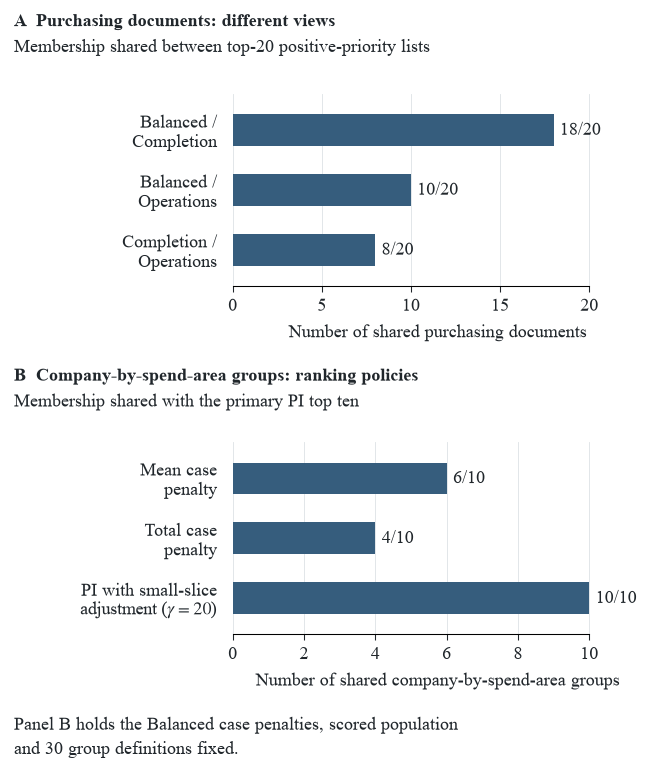

In [32]:
show_figure(paper.figure_6, "fig6_shortlists")

## 7. Applying the assessment to service management — Section 5.5

The six incident criteria retain uncertainty from missing team observations, timestamp ties and changing context. Repeated substatus observations and immediate returns are recorded patterns. Their illustrative thresholds do not establish a service commitment or failed resolution.

Compare PROD542 and PROD424 through their signed layers, then examine how the small-group adjustment changes their order. The incident criteria shown below belong to this application; they are separate from the purchase-to-pay table.

In [33]:
display(paper.incident_criteria())

,recorded condition,deviation scale,layer,w(Balanced),w(Routing),w(Timing)
criterion,,,,,,
C01,Observed support-team changes,"r(x; 2, 4)",Routing,1,3,1
C02,Immediate return to prior support team (compre...,"r(x; 0, 2)",Routing,1,3,1
C03,Repeated substatus observations beyond first o...,"r(x; 2, 8)",Recorded patterns,1,1,1
C04,Wait - User observed (not abuse),binary,Recorded patterns,1,1,1
C05,Long observed trace span (not resolution or se...,"r(x; 7, 23)",Timing,1,1,3
C06,Active status observed after Completed (not ce...,binary,Reactivation,1,1,2


### Incident population and product groups

In [34]:
show_result(paper.item_26_incident_log_size)

incidents     7554
events       65533
groups         704
criteria         6
Name: BPIC'13 incidents, dtype: int64

### PROD542 priority and signed explanations

In [35]:
show_result(paper.item_29_prod542)

mean_penalty                0.665994
scored                     75.000000
pi                         37.245645
layer.Routing              17.075672
layer.Recorded patterns    10.615626
layer.Timing                9.071557
layer.Reactivation          0.482791
Name: PROD542, dtype: float64

### PROD424 priority

In [36]:
show_result(paper.item_30_prod424)

mean_penalty                 0.205114
scored                     882.000000
pi                          31.512825
layer.Routing               -5.166766
layer.Recorded patterns     31.776426
layer.Timing                -0.094453
layer.Reactivation           4.997617
Name: PROD424, dtype: float64

### PROD424 signed layer contributions (item 37)

In [37]:
show_result(paper.item_37_prod424_layers)

Routing              -5.166766
Recorded patterns    31.776426
Timing               -0.094453
Reactivation          4.997617
Name: PROD424, dtype: float64

### Incident priorities with the small-group adjustment (item 38)

In [38]:
show_result(paper.item_38_incident_adjustment)

first.gamma0             PROD542
first.gamma20            PROD424
pi.gamma20.PROD424     30.814093
pi.gamma20.PROD542     29.404456
positive_in_top_ten           10
shared_top_ten                10
jaccard                      1.0
Name: Balanced, γ = 20, dtype: object

## 8. Applying the assessment to lending — Section 5.5

The application is the scored case. Lifecycle-specific work starts and reconciled offer identities remain part of the adapter policy. The five lending criteria define the assessment; three contribute to the Interaction view.

The comparison changes view weights and the small-group adjustment while retaining criterion results and case groups. Shortlist capacity is an upper bound: fewer than ten groups can have positive priority. Scores are not calibrated for comparisons between lending, service management and purchase-to-pay.

In [39]:
display(paper.lending_criteria())

,recorded condition,deviation scale,layer,scope,evidence,w(Balanced),w(Timeliness),w(Interaction)
criterion,,,,,,,,
C01,long recorded span; not completed cycle time o...,"r(x; 30, 30)",Timing,all applications,"at least two events, every timestamp timezone-...",1,4,1
C02,sum over W_ activities of max(number of START ...,"r(x; 0, 5)",Interaction,all applications,all event activity and lifecycle values present,1,1,3
C03,distinct recorded W_ START resource identifier...,"r(x; 2, 5)",Interaction,all applications,"activity and lifecycle complete, every W_ STAR...",1,1,3
C04,distinct observed offers associated with an ap...,"r(x; 1, 3)",Offer,any recorded O_ activity,activity and lifecycle complete and fully reco...,1,1,1
C05,number of COMPLETE A_Incomplete state records;...,"r(x; 0, 3)",Interaction,all applications,all event activity and lifecycle values present,1,1,3


### Lending population and evidence coverage (item 31)

In [40]:
show_result(paper.item_31_lending_log_size)

applications            31509
groups                     27
unavailable_in_scope        0
Name: BPIC'17, dtype: int64

### Highest-priority group under each view (item 32)

In [41]:
show_result(paper.item_32_lending_first_slices)

Balanced       New credit / Existing loan takeover
Timeliness        New credit / Remaining debt home
Interaction       New credit / Remaining debt home
Name: highest Priority Index, dtype: str

### Lending priorities and positive shortlist membership (item 39)

In [42]:
show_result(paper.item_39_lending_adjustment)

,"first, γ = 0","first, γ = 20",positive membership retained,positive groups at capacity ten
Balanced,New credit / Existing loan takeover,New credit / Existing loan takeover,True,4
Timeliness,New credit / Remaining debt home,New credit / Existing loan takeover,True,5
Interaction,New credit / Remaining debt home,New credit / Existing loan takeover,True,6


## 9. Numerical verification and evaluation limits — Section 5.6

The library checks three views in each of three applications: nine primary views and eighteen combinations of view and scoring mode. Each combination is checked at γ = 0 and γ = 20. The declared numerical tolerance is 1e-8; scope and evidence states require exact agreement.

The constructed checks test event-row order and norm serialisation on the bundled examples. The additional application checks start from prepared assessments and test case-record order, norm round trips and attached whole-case context. They guard numerical consistency and case alignment; they do not validate a business policy or establish an intervention’s effect.

In [43]:
show_result(paper.item_33_consistency_check)

applications                                              3
views per application                                     3
primary view evaluations                                  9
scoring modes                                             2
mode-view combinations                                   18
each checked at γ                                  0 and 20
largest absolute difference                             0.0
declared tolerance                                      0.0
below tolerance                                        True
scope and evidence states identical                    True
largest absolute difference, bpic2019                   0.0
largest absolute difference, bpic2013_incidents         0.0
largest absolute difference, bpic2017                   0.0
Name: consistency check, dtype: object

### Constructed checks of event-row order and norm serialisation (item 42)

In [44]:
show_result(paper.item_42_constructed_checks)

deviation values after shuffling the event rows: largest difference          0.0
deviation values preserved                                                  True
case scores after serialising and reloading the norm: largest difference     0.0
case scores preserved                                                       True
Name: constructed checks, dtype: object

### Further checks on the three prepared assessments

In [45]:
additional_checks = paper.further_checks()
display(additional_checks)
assert additional_checks["scores preserved"].all(), "A case-score consistency check failed."
assert additional_checks["norm fingerprint unchanged"].all(), "A norm fingerprint changed."


,cases reordered,norm serialised and read back,whole-case context attached,context,norm fingerprint unchanged,scores preserved
bpic2019,0.0,0.0,0.0,"document, vendor, flow",True,True
bpic2013_incidents,0.0,0.0,0.0,product_group,True,True
bpic2017,0.0,0.0,0.0,"application_type, loan_goal",True,True


### Source identity of each assessed application

In [46]:
for application in ("bpic2019", "bpic2013_incidents", "bpic2017"):
    show_result(lambda application=application: paper.input_identity(application))

file                                        BPI_Challenge_2019.csv
bytes                                                    527457189
sha256           7d592fb425690d13011d1b874fe2af63f61a66acfc368e...
events                                                     1595923
cases                                                       251734
documents                                                    76349
activities                                                      42
file_as_found                               BPI_Challenge_2019.csv
Name: bpic2019, dtype: object

file                           BPI_Challenge_2013_incidents.xes.gz
bytes                                                      1322247
sha256           6ec2136c607648608655802486df97a866f351668751b7...
events                                                       65533
cases                                                         7554
file_as_found                  bpi_challenge_2013_incidents.xes.gz
Name: bpic2013_incidents, dtype: object

file                                     BPI Challenge 2017.xes.gz
bytes                                                     29658747
sha256           183c5e5189282779c811c78c33ff936351b3dd201165d6...
events                                                     1202267
cases                                                        31509
file_as_found                            BPI Challenge 2017.xes.gz
Name: bpic2017, dtype: object

## 10. Printed and computed values for all 38 items

`compare()` compares computed and reference values at their declared tolerances; `summary()` aggregates agreement by item. A value that could not be computed remains visible and does not count as agreement.

The figures are drawn from the library’s assessment results. Their associated numeric items check the quantities displayed. Source identity is available separately from the numbered result items.

In [47]:
comparison = paper.compare()
display(comparison)
item_summary = paper.summary(comparison)
display(item_summary)

,item,place,quantity,printed,computed,agrees,status,note
0,1,"Table 4, p. 23; computations pp. 23-24",case A: violation of c2,0.75,0.75,True,agrees,
1,1,"Table 4, p. 23; computations pp. 23-24",case B: violation of c5,2/3 ≈ 0.67,0.666667,True,agrees,
2,1,"Table 4, p. 23; computations pp. 23-24",case C: violation of c3,0.65,0.65,True,agrees,
3,1,"Table 4, p. 23; computations pp. 23-24",case D: violation of c6,1,1.0,True,agrees,
4,1,"Table 4, p. 23; computations pp. 23-24",case E: violation of c1,1,1.0,True,agrees,
...,...,...,...,...,...,...,...,...
254,41,"Section 3, pp. 9-10; Fig. 2, p. 11",Financial control: Priority Index of Plant A,0,0.0,True,agrees,
255,41,"Section 3, pp. 9-10; Fig. 2, p. 11",Financial control: Priority Index of Plant B,0.65,0.65,True,agrees,
256,41,"Section 3, pp. 9-10; Fig. 2, p. 11",Financial control: first priority,Plant B,Plant B,True,agrees,
257,42,"Section 5.6, p. 33",deviation values unchanged after shuffling the...,yes,True,True,agrees,


,place,title,kind,values,agree,differ,not_computed,agrees
item,,,,,,,,
1,"Table 4, p. 23; computations pp. 23-24",Scores of the five illustrative cases under th...,result,17,17,0,0,True
2,"Section 4.2, pp. 16-18; Section 4.5, p. 25",Worked arithmetic of the method section,result,12,12,0,0,True
3,"Section 5.1, p. 27; Appendix B.1, p. 37",Size of the BPIC'19 export,result,3,3,0,0,True
4,"Appendix B.1, p. 37",Matching flows of the purchase-order items,result,4,4,0,0,True
5,"Section 5.1, p. 27; Appendix B.1, p. 37",Company-by-spend-area groups,result,1,1,0,0,True
6,"Section 5.1, p. 28; Appendix B.1, p. 38",All purchase-order items receive a score under...,result,3,3,0,0,True
7,"Section 5.1, p. 28",Mean weighted coverage per view,result,3,3,0,0,True
8,"Section 5.3, p. 29",C04 in Packaging,result,2,2,0,0,True
9,"Section 5.3, p. 29",Median selected invoice-to-clearing interval,result,4,4,0,0,True


In [48]:
if item_summary["differ"].any():
    raise AssertionError(
        "A computed result differs from its reference value; inspect the comparison."
    )
if item_summary["not_computed"].any():
    raise AssertionError(
        "Verification is incomplete: a required source result was not computed."
    )
if len(item_summary) != 38:
    raise AssertionError("The comparison must include all 38 result items.")
display(
    Markdown(
        f"All {len(comparison)} computed values agree with the paper "
        "at the declared precision and tolerances."
    )
)

All 259 computed values agree with the paper at the declared precision and tolerances.

## 11. Interpretation

The results distinguish source-log assessment, numerical consistency on prepared assessments and constructed examples. Evidence coverage measures the available in-scope weight; it does not establish compliance or log completeness. Signed layer contributions retain both positive contributions and negative offsets.

The rankings identify investigation priorities under the declared norm and comparison settings. Business interpretation requires inspection of the original records and confirmation of the applicable requirements. Operational improvement and intervention effects were not measured in these evaluations.
